# Decision Tree Regression

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from tqdm import tqdm

In [2]:
housing = pd.read_csv("../Datasets/Housing.csv")
housing.head()

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000.0,6360,2,1,1,yes,no,no,no,no,0,no


In [5]:
X,y = housing.drop("price",axis=1),housing["price"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [7]:
ohc = OneHotEncoder(sparse_output=False, drop="first").set_output(transform="pandas")
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),
                             ("passthrough", make_column_selector(dtype_include=['int64','float64'])),
                             verbose_feature_names_out=False)
ct = ct.set_output(transform='pandas')

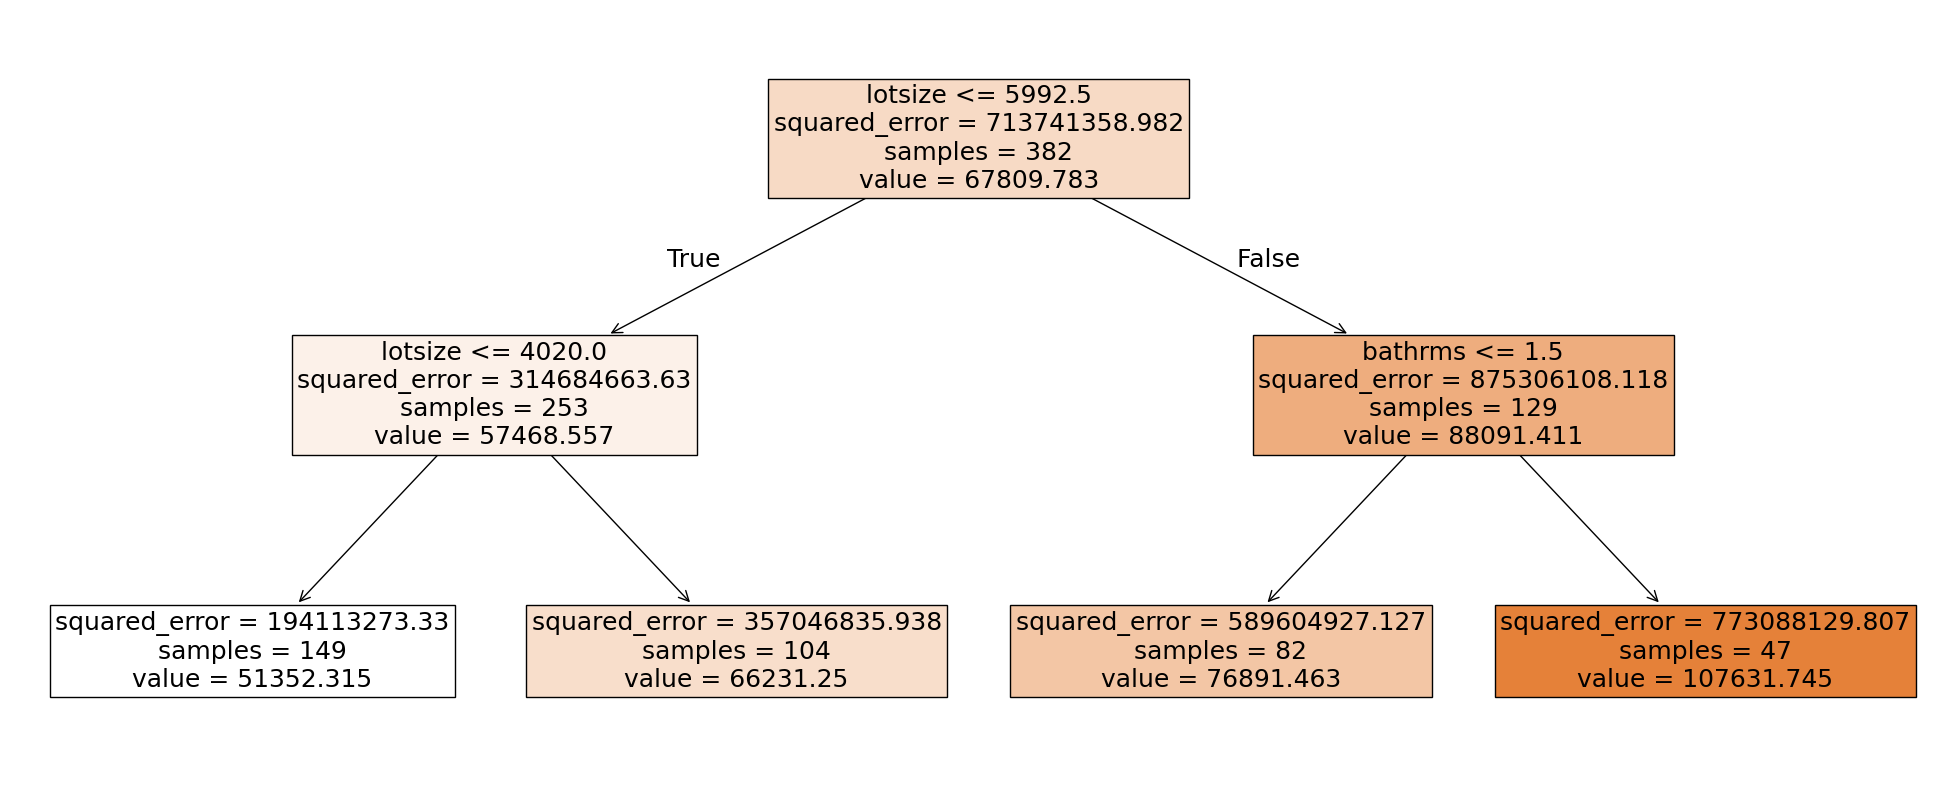

In [11]:
X_train_ohe = ct.fit_transform(X_train)
X_test_ohe = ct.fit_transform(X_test)
dtr = DecisionTreeRegressor(random_state=26,max_depth=2)
dtr.fit(X_train_ohe,y_train)
plt.figure(figsize=(25,10))
plot_tree(dtr,
          feature_names=list(X_train_ohe.columns),
          filled=True,
          fontsize=18)
plt.show()

In [15]:
y_pred = dtr.predict(X_test_ohe)
r2_score(y_test,y_pred)

0.4239320536357353

In [23]:
sq_error = np.sum(y_pred-np.mean(y))**2/housing.price.count()
sq_error

446344.2849467133

In [16]:
depths = [None,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for l in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26, max_depth=d, 
                                        min_samples_split=s, min_samples_leaf=l)
            pipe = Pipeline([("CT",ct),("TREE",dtr)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d,s,l,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","L","Scores"])
df_scores.sort_values("Scores",ascending=False)

100%|████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:05<00:00,  1.38it/s]


,D,S,L,Scores
157,5.0,0.01,0.05,0.526436
145,5.0,2.00,0.05,0.526436
19,NaN,0.10,0.05,0.526436
223,7.0,0.05,0.05,0.526436
199,6.0,0.10,0.05,0.526436
...,...,...,...,...
192,6.0,0.01,1.00,0.358850
228,7.0,0.01,1.00,0.308853
12,NaN,0.01,1.00,0.305639
0,NaN,2.00,1.00,0.286557


In [25]:
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,50]
min_leaf = [1,5,20,30,50]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for l in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26, max_depth=d, 
                                        min_samples_split=s, min_samples_leaf=l)
            pipe = Pipeline([("CT",ct),("TREE",dtr)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d,s,l,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","L","Scores"])
df_scores.sort_values("Scores",ascending=False)

100%|████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:02<00:00,  2.59it/s]


,D,S,L,Scores
17,NaN,50,20,0.530931
117,6.0,50,20,0.530931
97,5.0,50,20,0.530931
137,7.0,50,20,0.530931
96,5.0,50,5,0.528372
...,...,...,...,...
10,NaN,10,1,0.353734
125,7.0,5,1,0.329882
5,NaN,5,1,0.290221
0,NaN,2,1,0.286557


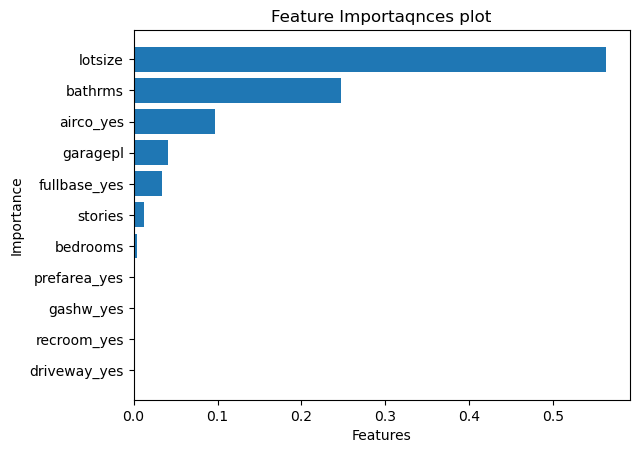

In [26]:
best_tree = DecisionTreeRegressor(random_state=26,max_depth=None,
                                  min_samples_split=50,min_samples_leaf=20)
X_ohe = ct.fit_transform(X)
best_tree.fit(X_ohe,y)
df_imp = pd.DataFrame({"features":list(X_ohe.columns),
                       "importance": best_tree.feature_importances_})
# plt.figure(figsize=(16,10))
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp["features"],df_imp["importance"])
plt.title("Feature Importaqnces plot")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()